# ML-08 — Capstone Modeling Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nando135/flyrank_ml_1/blob/main/work/notebooks/w05_model.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Method choice and why

*Which method from the toolkit, and why it fits your lane.*

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


I chose K-Means clustering because this lane focuses on grouping content into similar archetypes rather than predicting a known target label. K-Means fits this unsupervised setting by grouping pages based on similarities across their performance features. I will evaluate several values of \(k\) using silhouette score, then inspect the resulting clusters before assigning meaningful names to them.

## 2. Split design

*Grouped by client? Time-aware? Say why this split is honest for your question.*

In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


I will use a client-grouped train/validation split, where all pages from the same client stay in only one split. This is more honest than a random row split because pages from the same client may share similar traffic and engagement patterns. K-Means will be fitted only on the training clients, and the validation clients will then be assigned to the nearest learned cluster centroids. This tests whether the discovered content archetypes also make sense for unseen clients.

In [6]:
from google.colab import userdata
import duckdb
import pandas as pd

hf_token = userdata.get("HF_TOKEN")

con = duckdb.connect()

con.execute(f"""
CREATE SECRET (
    TYPE huggingface,
    TOKEN '{hf_token}'
)
""")

baseline_query = """
SELECT *
FROM read_parquet(
    'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/month=2026-03/*.parquet'
)
WHERE gsc_data_available IS TRUE
  AND ga4_data_available IS TRUE
"""

baseline_df = con.sql(baseline_query).df()

page_df = (
    baseline_df
    .groupby(["client_hash_id", "content_hash_id"], as_index=False)
    .agg(
        impressions=("gsc_impressions", "sum"),
        clicks=("gsc_clicks", "sum"),
        sessions=("ga4_sessions", "sum"),
        engaged_sessions=("ga4_engaged_sessions", "sum"),
        total_engagement_sec=("ga4_total_engagement_sec", "sum")
    )
)

page_df["ctr"] = (
    page_df["clicks"] / page_df["impressions"]
).fillna(0)

page_df["engagement_rate"] = (
    page_df["engaged_sessions"] / page_df["sessions"]
).fillna(0)

print("Pages:", len(page_df))
display(page_df.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Pages: 63856


,client_hash_id,content_hash_id,impressions,clicks,sessions,engaged_sessions,total_engagement_sec,ctr,engagement_rate
0,client_08d2847f24cf89c1,content_0071174ee1f89d8a,22,2,2,0,0,0.090909,0.0
1,client_08d2847f24cf89c1,content_07f1fdb8d2a0cf9d,186,7,7,0,2,0.037634,0.0
2,client_08d2847f24cf89c1,content_0f0c4d121b9d4aa5,8,1,4,0,0,0.125000,0.0
3,client_08d2847f24cf89c1,content_12444e383a53d45f,3,0,1,0,0,0.000000,0.0
4,client_08d2847f24cf89c1,content_145bbdb1286836a0,2,0,1,0,0,0.000000,0.0


In [7]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        page_df,
        groups=page_df["client_hash_id"]
    )
)

train_df = page_df.iloc[train_idx].copy()
val_df = page_df.iloc[val_idx].copy()

print("Training pages:", len(train_df))
print("Validation pages:", len(val_df))

print("Training clients:", train_df["client_hash_id"].nunique())
print("Validation clients:", val_df["client_hash_id"].nunique())

client_overlap = set(train_df["client_hash_id"]) & set(val_df["client_hash_id"])

print("Clients appearing in both splits:", len(client_overlap))

Training pages: 59679
Validation pages: 4177
Training clients: 27
Validation clients: 7
Clients appearing in both splits: 0


In [8]:
import numpy as np
from sklearn.preprocessing import StandardScaler

feature_cols = [
    "impressions",
    "ctr",
    "sessions",
    "engagement_rate"
]

train_features = train_df[feature_cols].copy()
val_features = val_df[feature_cols].copy()

train_features["impressions"] = np.log1p(train_features["impressions"])
train_features["sessions"] = np.log1p(train_features["sessions"])

val_features["impressions"] = np.log1p(val_features["impressions"])
val_features["sessions"] = np.log1p(val_features["sessions"])

scaler = StandardScaler()

X_train = scaler.fit_transform(train_features)
X_val = scaler.transform(val_features)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)

X_train shape: (59679, 4)
X_val shape: (4177, 4)


## 3. Train + compare vs my baseline

*Same data, same metric, same split as your Week-4 baseline. Show the table.*

In [9]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

k_values = [2, 3, 4, 5, 6]

results = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    train_labels = model.fit_predict(X_train)

    silhouette = silhouette_score(
        X_train,
        train_labels
    )

    inertia = model.inertia_

    results.append({
        "k": k,
        "silhouette_score": silhouette,
        "inertia": inertia
    })

results_df = pd.DataFrame(results)

display(results_df)

,k,silhouette_score,inertia
0,2,0.411049,161699.885683
1,3,0.447923,112166.310851
2,4,0.479598,73130.845161
3,5,0.391072,56618.314539
4,6,0.408007,46247.504480


elbow method

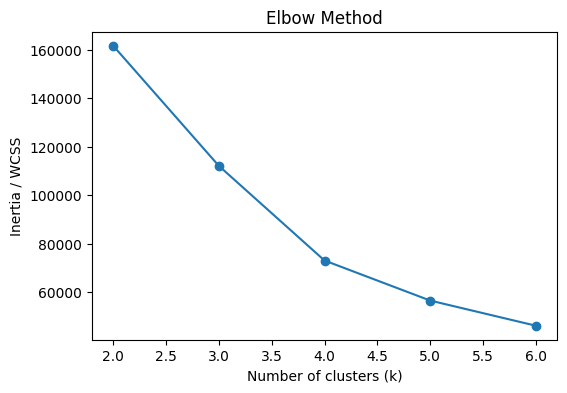

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.plot(
    results_df["k"],
    results_df["inertia"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia / WCSS")
plt.title("Elbow Method")

plt.show()

silhouette method

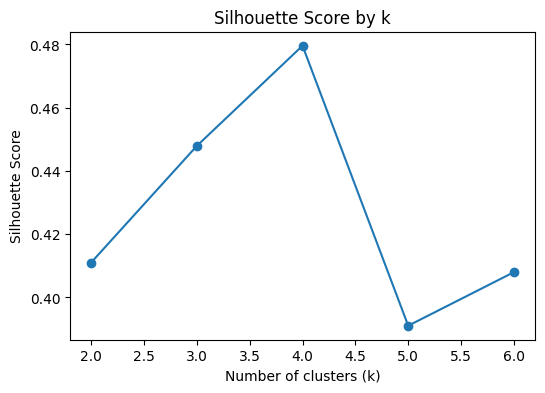

In [11]:
plt.figure(figsize=(6, 4))

plt.plot(
    results_df["k"],
    results_df["silhouette_score"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by k")

plt.show()

In [12]:
final_k = 4

final_model = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

train_clusters = final_model.fit_predict(X_train)
val_clusters = final_model.predict(X_val)

train_df["cluster"] = train_clusters
val_df["cluster"] = val_clusters

print("Training cluster counts:")
print(train_df["cluster"].value_counts().sort_index())

print("\nValidation cluster counts:")
print(val_df["cluster"].value_counts().sort_index())

Training cluster counts:
cluster
0    34153
1    23398
2     1008
3     1120
Name: count, dtype: int64

Validation cluster counts:
cluster
0    3504
1     404
2     150
3     119
Name: count, dtype: int64


In [13]:
cluster_summary = (
    train_df
    .groupby("cluster")
    .agg(
        n=("content_hash_id", "count"),
        median_impressions=("impressions", "median"),
        median_ctr=("ctr", "median"),
        median_sessions=("sessions", "median"),
        median_engagement_rate=("engagement_rate", "median")
    )
    .reset_index()
)

display(cluster_summary)

,cluster,n,median_impressions,median_ctr,median_sessions,median_engagement_rate
0,0,34153,33.0,0.000000,2.0,0.000000
1,1,23398,1222.0,0.004229,23.0,0.000000
2,2,1008,1.0,1.000000,1.0,0.000000
3,3,1120,22.5,0.014519,2.0,0.666667


validation

In [14]:
val_cluster_summary = (
    val_df
    .groupby("cluster")
    .agg(
        n=("content_hash_id", "count"),
        median_impressions=("impressions", "median"),
        median_ctr=("ctr", "median"),
        median_sessions=("sessions", "median"),
        median_engagement_rate=("engagement_rate", "median")
    )
    .reset_index()
)

display(val_cluster_summary)

,cluster,n,median_impressions,median_ctr,median_sessions,median_engagement_rate
0,0,3504,13.0,0.000000,1.0,0.000000
1,1,404,958.0,0.006306,10.0,0.000000
2,2,150,1.0,1.000000,1.0,0.000000
3,3,119,10.0,0.030303,2.0,0.666667


In [15]:
from sklearn.metrics import silhouette_score

train_silhouette = silhouette_score(
    X_train,
    train_clusters
)

val_silhouette = silhouette_score(
    X_val,
    val_clusters
)

print("Training silhouette:", train_silhouette)
print("Validation silhouette:", val_silhouette)

Training silhouette: 0.479598181061736
Validation silhouette: 0.4659947653606159


comparison

In [16]:
baseline_val = val_df.copy()

baseline_val["visibility_score"] = (
    baseline_val["impressions"].rank(pct=True)
)

baseline_val["low_ctr_score"] = (
    1 - baseline_val["ctr"].rank(pct=True)
)

baseline_val["low_engagement_score"] = (
    1 - baseline_val["engagement_rate"].rank(pct=True)
)

baseline_val["baseline_score"] = (
    0.40 * baseline_val["visibility_score"]
    + 0.40 * baseline_val["low_ctr_score"]
    + 0.20 * baseline_val["low_engagement_score"]
)

baseline_val["baseline_group"] = pd.qcut(
    baseline_val["baseline_score"],
    q=4,
    labels=False,
    duplicates="drop"
)

baseline_silhouette = silhouette_score(
    X_val,
    baseline_val["baseline_group"]
)

print("Baseline silhouette:", baseline_silhouette)
print("K-Means validation silhouette:", val_silhouette)

Baseline silhouette: -0.06959044225481038
K-Means validation silhouette: 0.4659947653606159


In [17]:
comparison_df = pd.DataFrame({
    "method": [
        "Week 4 rule baseline",
        "K-Means"
    ],
    "validation_silhouette": [
        baseline_silhouette,
        val_silhouette
    ]
})

display(comparison_df)

,method,validation_silhouette
0,Week 4 rule baseline,-0.069590
1,K-Means,0.465995


K-Means clearly outperformed the Week 4 rule baseline for the clustering objective. The baseline priority bands produced a validation silhouette score of -0.070, indicating poor separation between groups, while K-Means achieved 0.466 on unseen clients. This suggests that the learned clusters capture more coherent content archetypes than the manually weighted baseline score. However, the Week 4 baseline was originally designed for action prioritization rather than clustering, so this comparison should be interpreted as a geometric grouping comparison rather than a replacement of its original purpose.

## 4. Errors and interpretation

*Where is the model wrong? What does it lean on? A short error analysis beats a big metric table.*

In [18]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import numpy as np

assigned_centroids = final_model.cluster_centers_[val_clusters]

val_distances = np.linalg.norm(
    X_val - assigned_centroids,
    axis=1
)

error_df = val_df[
    [
        "client_hash_id",
        "content_hash_id",
        "impressions",
        "ctr",
        "sessions",
        "engagement_rate",
        "cluster"
    ]
].copy()

error_df["distance_to_centroid"] = val_distances

error_df = error_df.sort_values(
    "distance_to_centroid",
    ascending=False
)

display(error_df.head(10))

,client_hash_id,content_hash_id,impressions,ctr,sessions,engagement_rate,cluster,distance_to_centroid
46263,client_def0955f7a377868,content_374e1a9240c7949f,1,1.0,1,1.0,3,7.998262
42003,client_a80fca3f171ed1de,content_2a2ba386d09fb478,1,1.0,1,1.0,3,7.998262
43294,client_a80fca3f171ed1de,content_a23472f29310f631,1,1.0,1,1.0,3,7.998262
42875,client_a80fca3f171ed1de,content_7a4ecaa6e20c055f,1,1.0,1,1.0,3,7.998262
42669,client_a80fca3f171ed1de,content_65999f69444bb0f3,1,1.0,1,1.0,3,7.998262
43320,client_a80fca3f171ed1de,content_a46d84f316579450,1,1.0,1,1.0,3,7.998262
22357,client_3197e6291363b4db,content_034cffb71ce8f33b,1,1.0,1,1.0,3,7.998262
43626,client_a80fca3f171ed1de,content_c263cc7e039e69aa,1,1.0,1,1.0,3,7.998262
43737,client_a80fca3f171ed1de,content_cc80291a1ea071e5,2,0.5,1,1.0,3,4.121299
42222,client_a80fca3f171ed1de,content_3e671deed5a053ae,2,0.5,1,1.0,3,4.121299


The largest cluster errors occur on very low-volume pages with extreme rates. Several validation pages have only 1 impression and 1 session but have CTR = 1.0 and engagement rate = 1.0. These points are far from their assigned centroid because a single click or engaged session produces a 100% rate. This shows that K-Means is sensitive to unstable rate values when denominators are very small. A future version could add minimum-volume eligibility rules or use smoothed rate features before clustering.

In [19]:
centroids_scaled = final_model.cluster_centers_

centroids_original = scaler.inverse_transform(centroids_scaled)

centroids_df = pd.DataFrame(
    centroids_original,
    columns=feature_cols
)

centroids_df["impressions"] = np.expm1(
    centroids_df["impressions"]
)

centroids_df["sessions"] = np.expm1(
    centroids_df["sessions"]
)

centroids_df["cluster"] = range(final_k)

display(
    centroids_df[
        [
            "cluster",
            "impressions",
            "ctr",
            "sessions",
            "engagement_rate"
        ]
    ]
)

,cluster,impressions,ctr,sessions,engagement_rate
0,0,31.252657,0.019055,2.299536,0.010073
1,1,1282.863880,0.006208,26.414820,0.027941
2,2,1.521881,0.804707,1.194006,0.011278
3,3,22.919359,0.107891,1.691564,0.741263


The clusters are mainly separated by visibility volume, CTR, and engagement rate. Cluster 1 is driven by much higher impressions and sessions, Cluster 2 by extremely high CTR on very small volumes, and Cluster 3 by high engagement rate. This also confirms the earlier error analysis: rate features can dominate when denominators are very small, especially in Cluster 2 and some Cluster 3 cases.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.